# Практикум 3 · Airflow
**user1** · шесть разобранных примеров и семь собственных DAG. Ниже код файлов и фактические результаты, полученные через REST API. Большие объекты хранятся в S3, XCom содержит лишь ссылки и небольшие сводки.

In [1]:
import os, requests, time, ast, uuid
from pathlib import Path
import pandas as pd, boto3, mlflow
from IPython.display import Image
DAG_DIR=next(p.resolve() for p in [Path('../../dags'),Path('../../../dags')] if (p/'user1_p7_churn.py').exists())
base='http://airflow-webserver:8080/api/v1'; auth=('student','student'); s3=boto3.client('s3',endpoint_url=os.environ['S3_ENDPOINT_URL']); batch=uuid.uuid4().hex[:8]
def api(method,path,**kw):
    r=requests.request(method,base+path,auth=auth,timeout=30,**kw);r.raise_for_status();return r.json()
def wait(fn,seconds=1100):
    deadline=time.monotonic()+seconds
    while time.monotonic()<deadline:
        val=fn()
        if val:return val
        time.sleep(3)
    raise TimeoutError('Ожидание Airflow истекло')
print(DAG_DIR,api('GET','/health')['scheduler'])

/home/user/ml_2/data-stack/dags {'latest_scheduler_heartbeat': '2026-11-19T20:17:20.467345+00:00', 'status': 'healthy'}


### Пример · Последовательность задач

In [2]:
%%writefile {DAG_DIR}/user1_first.py
'''Первый DAG: extract → transform → load. Данные — Iris.'''

from datetime import timedelta

import pendulum
from airflow.decorators import dag, task

STUDENT = "user1"        # <-- ваш логин (в имени файла он тоже должен быть)


@dag(
    dag_id=f"{STUDENT}_first",                    # имя DAG-а в интерфейсе
    schedule=None,                                # расписание нет — запускаем сами, кнопкой
    start_date=pendulum.datetime(2026, 1, 1),     # с какой даты существует конвейер
    catchup=False,                                # не «догонять» пропущенные даты
    tags=[STUDENT],                               # по тегу удобно фильтровать свои DAG-и
    default_args={"owner": STUDENT, "retries": 1, "retry_delay": timedelta(seconds=15)},
)
def first():
    '''Три задачи по порядку.'''

    @task
    def extract() -> dict:
        '''Шаг 1: берём данные. Тяжёлые импорты — внутри задачи: файл DAG-а перечитывается часто.'''
        from sklearn.datasets import load_iris

        data = load_iris(as_frame=True).frame
        return {                                   # наружу — только маленький словарь
            "rows": len(data),
            "means": data.mean(numeric_only=True).round(2).to_dict(),
        }

    @task
    def transform(info: dict) -> dict:
        '''Шаг 2: из средних выбираем колонку с максимальным средним.'''
        means = info["means"]
        top = max(means, key=means.get)
        return {"rows": info["rows"], "top_feature": top, "top_mean": means[top]}

    @task
    def load(report: dict) -> str:
        '''Шаг 3: печатаем отчёт (в разделе 7 научимся сохранять в S3).'''
        print(f"Iris: {report['rows']} строк; максимальное среднее у «{report['top_feature']}» "
              f"= {report['top_mean']}")
        return "готово"

    load(transform(extract()))                     # вот и весь порядок: extract → transform → load


first()                                            # вызов в конце файла обязателен

Writing /home/user/ml_2/data-stack/dags/user1_first.py


### Пример · Параллельные ветви

In [3]:
%%writefile {DAG_DIR}/user1_parallel.py
'''Параллельные задачи: prepare → три обучения → select_best. Данные — wine.'''

import pendulum
from airflow.decorators import dag, task

STUDENT = "user1"


@dag(dag_id=f"{STUDENT}_parallel", schedule=None,
     start_date=pendulum.datetime(2026, 1, 1), catchup=False, tags=[STUDENT])
def parallel():

    @task
    def prepare() -> dict:
        '''Готовит данные. Таблицу между задачами не передаём (XCom — только маленькое):
        каждая задача обучения повторит разбиение с тем же random_state и получит те же выборки.'''
        from sklearn.datasets import load_wine
        from sklearn.model_selection import train_test_split

        data = load_wine(as_frame=True).frame
        train, test = train_test_split(data, test_size=0.25, random_state=42, stratify=data["target"])
        return {"train_rows": len(train), "test_rows": len(test)}

    @task
    def train(model_name: str, sizes: dict) -> dict:
        '''Обучает одну модель. Три такие задачи идут параллельно.'''
        from sklearn.datasets import load_wine
        from sklearn.linear_model import LogisticRegression
        from sklearn.model_selection import train_test_split
        from sklearn.neighbors import KNeighborsClassifier
        from sklearn.pipeline import make_pipeline
        from sklearn.preprocessing import StandardScaler
        from sklearn.tree import DecisionTreeClassifier

        data = load_wine(as_frame=True).frame
        train, test = train_test_split(data, test_size=0.25, random_state=42, stratify=data["target"])

        models = {
            "logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
            "knn": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
            "tree": DecisionTreeClassifier(max_depth=3, random_state=42),
        }
        model = models[model_name].fit(train.drop(columns="target"), train["target"])
        accuracy = model.score(test.drop(columns="target"), test["target"])
        return {"model": model_name, "accuracy": round(accuracy, 4)}

    @task
    def select_best(r1: dict, r2: dict, r3: dict) -> dict:
        results = [r1, r2, r3]
        best = max(results, key=lambda r: r["accuracy"])
        print("результаты:", [(r["model"], r["accuracy"]) for r in results])
        print("лучший:", best["model"])
        return best

    sizes = prepare()
    select_best(train("logreg", sizes), train("knn", sizes), train("tree", sizes))


parallel()

Writing /home/user/ml_2/data-stack/dags/user1_parallel.py


### Пример · Случайный сбой и повтор

In [4]:
%%writefile {DAG_DIR}/user1_retry.py
'''Задача-врун: падает в половине случаев. Смотрим, как Airflow повторяет попытки.'''

import random
from datetime import timedelta

import pendulum
from airflow.decorators import dag, task

STUDENT = "user1"


@dag(dag_id=f"{STUDENT}_retry", schedule=None,
     start_date=pendulum.datetime(2026, 1, 1), catchup=False, tags=[STUDENT])
def retry():

    @task(retries=4, retry_delay=timedelta(seconds=10))   # упала — повторить ещё 4 раза
    def flaky() -> str:
        if random.random() < 0.5:
            raise RuntimeError("временный сбой: «база не ответила» (учебная ошибка)")
        return "ok"

    @task
    def report(status: str):
        print("итог:", status)

    report(flaky())


retry()

Writing /home/user/ml_2/data-stack/dags/user1_retry.py


### Пример · S3Hook и Parquet

In [5]:
%%writefile {DAG_DIR}/user1_s3hook.py
'''DAG и S3: prepare → check. Ключ — по дате запуска ds.'''

import io

import pendulum
from airflow.decorators import dag, task
from airflow.providers.amazon.aws.hooks.s3 import S3Hook

STUDENT = "user1"
BUCKET = STUDENT                                  # бакет называется вашим логином


@dag(dag_id=f"{STUDENT}_s3hook", schedule=None,
     start_date=pendulum.datetime(2026, 1, 1), catchup=False, tags=[STUDENT])
def s3hook_demo():

    @task
    def prepare(ds=None) -> str:
        '''ds — дата запуска (например 2026-11-06): у каждого запуска своя «папка» в S3.'''
        from sklearn.datasets import load_iris

        df = load_iris(as_frame=True).frame
        buf = io.BytesIO()
        df.to_parquet(buf, index=False)            # DataFrame -> parquet (буфер в памяти)

        key = f"airflow/{ds}/iris.parquet"
        S3Hook(aws_conn_id="s3_local").load_bytes(  # байты -> S3, ключи берёт из Connection
            buf.getvalue(), key=key, bucket_name=BUCKET, replace=True)
        return key                                 # дальше передаём только ключ

    @task
    def check(key: str):
        hook = S3Hook(aws_conn_id="s3_local")
        print("файл на месте:", hook.check_for_key(key, bucket_name=BUCKET))
        print("в airflow/ лежит:", hook.list_keys(prefix="airflow/", bucket_name=BUCKET))

    check(prepare())


s3hook_demo()

Writing /home/user/ml_2/data-stack/dags/user1_s3hook.py


### Пример · PostgresHook

In [6]:
%%writefile {DAG_DIR}/user1_pg.py
'''DAG и PostgreSQL: обучаем модель, метрику — в таблицу, читаем обратно.'''

import pendulum
from airflow.decorators import dag, task
from airflow.providers.postgres.hooks.postgres import PostgresHook

STUDENT = "user1"


def pg():
    return PostgresHook(postgres_conn_id="postgres_main")


@dag(dag_id=f"{STUDENT}_pg", schedule=None,
     start_date=pendulum.datetime(2026, 1, 1), catchup=False, tags=[STUDENT])
def pg_demo():

    @task
    def init() -> str:
        '''Своя схема и таблица метрик (IF NOT EXISTS — можно запускать много раз).'''
        pg().run(f'CREATE SCHEMA IF NOT EXISTS "{STUDENT}"')
        pg().run(f'''CREATE TABLE IF NOT EXISTS "{STUDENT}".runs (
                          ds TEXT, task TEXT, metric DOUBLE PRECISION,
                          created_at TIMESTAMP DEFAULT now())''')
        return "ok"

    @task
    def train(ok: str, ds=None) -> float:
        from sklearn.datasets import load_iris
        from sklearn.linear_model import LogisticRegression
        from sklearn.model_selection import train_test_split
        from sklearn.pipeline import make_pipeline
        from sklearn.preprocessing import StandardScaler

        data = load_iris(as_frame=True).frame
        train_df, test_df = train_test_split(data, test_size=0.25, random_state=42,
                                             stratify=data["target"])
        model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
        model.fit(train_df.drop(columns="target"), train_df["target"])
        accuracy = model.score(test_df.drop(columns="target"), test_df["target"])

        pg().insert_rows(f'"{STUDENT}".runs', rows=[(ds, "train_logreg", round(accuracy, 4))])
        return round(accuracy, 4)

    @task
    def read_back(accuracy: float):
        rows = pg().get_records(
            f'SELECT ds, task, metric FROM "{STUDENT}".runs ORDER BY created_at DESC LIMIT 5')
        print("accuracy этой задачи:", accuracy)
        print("последние строки в базе:")
        for row in rows:
            print("  ", row)

    read_back(train(init()))


pg_demo()

Writing /home/user/ml_2/data-stack/dags/user1_pg.py


### Пример · S3 → две модели → реестр

In [7]:
%%writefile {DAG_DIR}/user1_full.py
'''Полный конвейер: данные → S3 → две модели параллельно (обе в MLflow) → лучшая в реестр → прогноз.'''

import os

import pendulum
from airflow.decorators import dag, task
from airflow.models import Variable

STUDENT = "user1"
EXPERIMENT = f"{STUDENT}_airflow"           # эксперимент в MLflow
MODEL_NAME = f"{STUDENT}_airflow_model"     # модель в реестре


def mlflow_on():
    '''MLflow из задачи: адрес — окружение, логин — ваш, пароль — из Airflow Variable.'''
    import mlflow

    os.environ.setdefault("MLFLOW_TRACKING_URI", "http://mlflow:5000")
    os.environ["MLFLOW_TRACKING_USERNAME"] = STUDENT
    os.environ["MLFLOW_TRACKING_PASSWORD"] = Variable.get(f"{STUDENT}_mlflow_password",
                                                          default_var="")
    return mlflow


def log_sklearn_model(mlflow, model, X_example):
    '''Сохраняет sklearn-модель в текущий запуск (формат skops — как в практикуме 2).'''
    import skops.io as sio
    from mlflow.models import infer_signature

    return mlflow.sklearn.log_model(
        model, name="model", pip_requirements=["scikit-learn==1.6.1", "skops==0.16.0"],
        signature=infer_signature(X_example, model.predict(X_example)),
        input_example=X_example.head(3),
        skops_trusted_types=sio.get_untrusted_types(data=sio.dumps(model)),
    )


@dag(dag_id=f"{STUDENT}_full", schedule=None,
     start_date=pendulum.datetime(2026, 1, 1), catchup=False, tags=[STUDENT])
def full():

    @task
    def prepare(ds=None) -> str:
        '''Breast Cancer → S3 (parquet). Наружу — ключ.'''
        import io
        from airflow.providers.amazon.aws.hooks.s3 import S3Hook
        from sklearn.datasets import load_breast_cancer

        df = load_breast_cancer(as_frame=True).frame
        buf = io.BytesIO()
        df.to_parquet(buf, index=False)
        key = f"airflow/{ds}/cancer.parquet"
        S3Hook(aws_conn_id="s3_local").load_bytes(buf.getvalue(), key=key,
                                                  bucket_name=STUDENT, replace=True)
        return key

    @task
    def train(model_name: str, key: str) -> dict:
        '''Обучает одну модель и пишет запуск в MLflow. Две задачи train идут параллельно.'''
        import pandas as pd
        from airflow.providers.amazon.aws.hooks.s3 import S3Hook
        from sklearn.ensemble import RandomForestClassifier
        from sklearn.linear_model import LogisticRegression
        from sklearn.metrics import roc_auc_score
        from sklearn.model_selection import train_test_split
        from sklearn.pipeline import make_pipeline
        from sklearn.preprocessing import StandardScaler

        local = S3Hook(aws_conn_id="s3_local").download_file(key=key, bucket_name=STUDENT)   # вернёт путь к файлу
        df = pd.read_parquet(local)

        train_df, test_df = train_test_split(df, test_size=0.25, random_state=42,
                                             stratify=df["target"])
        models = {
            "logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
            "random_forest": RandomForestClassifier(random_state=42),
        }
        X_test, y_test = test_df.drop(columns="target"), test_df["target"]

        model = models[model_name].fit(train_df.drop(columns="target"), train_df["target"])
        auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])

        mlflow = mlflow_on()
        mlflow.set_experiment(EXPERIMENT)
        with mlflow.start_run(run_name=model_name) as run:
            mlflow.log_param("model", model_name)
            mlflow.log_metric("roc_auc", round(auc, 4))
            log_sklearn_model(mlflow, model, X_test)
        return {"model": model_name, "roc_auc": round(auc, 4), "run_id": run.info.run_id}

    @task
    def select_best(r1: dict, r2: dict) -> dict:
        best = max([r1, r2], key=lambda r: r["roc_auc"])
        print(f"{r1['model']}: {r1['roc_auc']} | {r2['model']}: {r2['roc_auc']}"
              f" → лучший: {best['model']}")
        return best

    @task
    def register_and_predict(best: dict):
        from sklearn.datasets import load_breast_cancer

        mlflow = mlflow_on()
        version = mlflow.register_model(f"runs:/{best['run_id']}/model", MODEL_NAME)
        mlflow.MlflowClient().set_registered_model_alias(MODEL_NAME, "champion", version.version)

        champion = mlflow.sklearn.load_model(f"models:/{MODEL_NAME}@champion")
        X, _ = load_breast_cancer(return_X_y=True, as_frame=True)
        print(f"реестр: {MODEL_NAME}, новая версия {version.version} ({best['model']}) — метка @champion")
        print("прогноз чемпиона для 3 строк:", champion.predict(X.head(3)).tolist())

    key = prepare()
    register_and_predict(select_best(train("logreg", key), train("random_forest", key)))


full()

Writing /home/user/ml_2/data-stack/dags/user1_full.py


### Задача 1. Первый DAG
Сделайте `user1_step1.py`: `extract → transform → load` на датасете **wine**.
`extract` возвращает число строк и средние значения колонок; `transform` выбирает колонку
с максимальным средним; `load` печатает отчёт. Запустите и покажите лог `load` и XCom задачи
`transform`.


In [8]:
%%writefile {DAG_DIR}/user1_step1.py
import pendulum
from airflow.decorators import dag, task
from datetime import timedelta

@dag(dag_id='user1_step1',schedule=None,start_date=pendulum.datetime(2026,1,1),catchup=False,tags=['user1'])
def step1():
    @task
    def extract():
        from sklearn.datasets import load_wine
        df=load_wine(as_frame=True).data
        return {'rows':len(df),'means':df.mean().to_dict()}
    @task
    def transform(info):
        name=max(info['means'],key=info['means'].get)
        return {'rows':info['rows'],'column':name,'mean':info['means'][name]}
    @task
    def load(report):
        print(report);return report
    load(transform(extract()))

step1()

Writing /home/user/ml_2/data-stack/dags/user1_step1.py


### Задача 2. Параллельность и повторы
`user1_step2.py` на **iris**: `prepare` (разбиение train/test, `random_state=42`) → три
**параллельных** обучения (`logreg`, `knn`, `tree`) → `select_best` по accuracy на тесте.
Одной из задач обучения поставьте `retries=3` и добавьте в неё «временный сбой»
(`random.random() < 0.3 → raise`). В Grid найдите оранжевый квадратик и повтор в логе.


In [9]:
%%writefile {DAG_DIR}/user1_step2.py
import pendulum
from airflow.decorators import dag, task
from datetime import timedelta

@dag(dag_id='user1_step2',schedule=None,start_date=pendulum.datetime(2026,1,1),catchup=False,tags=['user1'])
def step2():
    @task
    def prepare():
        from sklearn.datasets import load_iris
        from sklearn.model_selection import train_test_split
        d=load_iris(as_frame=True).frame
        a,b=train_test_split(d,test_size=.25,stratify=d.target,random_state=42)
        from churn7_core import put
        for k,v in [('train',a),('test',b)]:put('practice/iris/'+k+'.parquet',v.to_parquet(index=False))
        return {'train':'practice/iris/train.parquet','test':'practice/iris/test.parquet'}
    @task
    def train(name,keys):
        import random,pandas as pd
        from churn7_core import read
        from sklearn.neighbors import KNeighborsClassifier
        from sklearn.tree import DecisionTreeClassifier
        from sklearn.linear_model import LogisticRegression
        if name=='tree' and random.random()<.3:raise RuntimeError('Временный сбой дерева')
        a,b=[pd.read_parquet(read(keys[k])) for k in ('train','test')]
        m={'logreg':LogisticRegression(max_iter=500),'knn':KNeighborsClassifier(),'tree':DecisionTreeClassifier(random_state=42)}[name]
        m.fit(a.drop(columns='target'),a.target)
        return {'model':name,'accuracy':m.score(b.drop(columns='target'),b.target)}
    @task
    def select_best(results):return max(results,key=lambda r:r['accuracy'])
    keys=prepare();select_best([train.override(task_id='train_'+k,retries=3 if k=='tree' else 0,retry_delay=timedelta(seconds=10))(k,keys) for k in ['logreg','knn','tree']])

step2()

Writing /home/user/ml_2/data-stack/dags/user1_step2.py


### Задача 3. Данные в S3 и PostgreSQL
`user1_step3.py`: `prepare` кладёт iris в S3 как parquet по ключу `airflow/{ds}/iris.parquet`
и возвращает ключ; `train` читает его (`download_file`), обучает логрег и пишет accuracy
в таблицу `"{STUDENT}".runs` (схему и таблицу создайте в этой же задаче, как в разделе 8);
`read_back` печатает последние 5 строк. Проверьте `ls("airflow/")` из Jupyter.


In [10]:
%%writefile {DAG_DIR}/user1_step3.py
import pendulum
from airflow.decorators import dag, task
from datetime import timedelta

@dag(dag_id='user1_step3',schedule=None,start_date=pendulum.datetime(2026,1,1),catchup=False,tags=['user1'])
def step3():
    @task
    def prepare(ds=None):
        from sklearn.datasets import load_iris
        from airflow.providers.amazon.aws.hooks.s3 import S3Hook
        key=f'airflow/{ds}/iris.parquet';S3Hook(aws_conn_id='s3_local').load_bytes(load_iris(as_frame=True).frame.to_parquet(index=False),key,'user1',replace=True);return key
    @task
    def train(key,ds=None):
        import pandas as pd
        from tempfile import TemporaryDirectory
        from airflow.providers.amazon.aws.hooks.s3 import S3Hook
        from airflow.providers.postgres.hooks.postgres import PostgresHook
        from sklearn.linear_model import LogisticRegression
        from sklearn.model_selection import train_test_split
        with TemporaryDirectory() as tmp: d=pd.read_parquet(S3Hook(aws_conn_id='s3_local').download_file(key,'user1',local_path=tmp))
        a,b=train_test_split(d,test_size=.25,stratify=d.target,random_state=42);m=LogisticRegression(max_iter=500).fit(a.drop(columns='target'),a.target);accuracy=m.score(b.drop(columns='target'),b.target)
        pg=PostgresHook(postgres_conn_id='postgres_main');pg.run('CREATE SCHEMA IF NOT EXISTS user1');pg.run('CREATE TABLE IF NOT EXISTS user1.runs(ds text, task text, metric double precision, created_at timestamp default now())');pg.insert_rows('user1.runs',[(ds,'step3_train',accuracy)],target_fields=['ds','task','metric']);return accuracy
    @task
    def read_back(accuracy):
        from airflow.providers.postgres.hooks.postgres import PostgresHook
        print(PostgresHook(postgres_conn_id='postgres_main').get_records('SELECT * FROM user1.runs ORDER BY created_at DESC LIMIT 5'))
    read_back(train(prepare()))

step3()

Writing /home/user/ml_2/data-stack/dags/user1_step3.py


### Задача 4. Модель и артефакты в S3
`user1_step4.py` на **breast cancer**: `prepare` → train/test parquet в S3; `train` обучает
логрег и кладёт в S3 `model.joblib`, `metrics.json` (accuracy и roc_auc) и `confusion_matrix.png`;
`predict` загружает модель из S3 и печатает прогноз для 5 строк теста. MLflow здесь не нужен —
только S3. Проверьте `ls()` и откройте картинку из Jupyter (как в практикуме 1).


In [11]:
%%writefile {DAG_DIR}/user1_step4.py
import pendulum
from airflow.decorators import dag, task
from datetime import timedelta

@dag(dag_id='user1_step4',schedule=None,start_date=pendulum.datetime(2026,1,1),catchup=False,tags=['user1'])
def step4():
    @task
    def prepare(ds=None):
        from sklearn.datasets import load_breast_cancer
        from sklearn.model_selection import train_test_split
        from churn7_core import put
        d=load_breast_cancer(as_frame=True).frame;a,b=train_test_split(d,test_size=.25,stratify=d.target,random_state=42);prefix=f'airflow/{ds}/step4/'
        for k,v in [('train',a),('test',b)]:put(prefix+k+'.parquet',v.to_parquet(index=False))
        return {'train':prefix+'train.parquet','test':prefix+'test.parquet','prefix':prefix}
    @task
    def train(keys):
        import io,json,joblib,pandas as pd
        from churn7_core import read,put
        from sklearn.preprocessing import StandardScaler
        from sklearn.linear_model import LogisticRegression
        from sklearn.pipeline import make_pipeline
        from sklearn.metrics import roc_auc_score,ConfusionMatrixDisplay
        a,b=[pd.read_parquet(read(keys[k])) for k in ('train','test')]; x=b.drop(columns='target');m=make_pipeline(StandardScaler(),LogisticRegression(max_iter=500)).fit(a.drop(columns='target'),a.target)
        buf=io.BytesIO();joblib.dump(m,buf);prefix=keys['prefix'];put(prefix+'model.joblib',buf.getvalue());put(prefix+'metrics.json',json.dumps({'accuracy':m.score(x,b.target),'roc_auc':roc_auc_score(b.target,m.predict_proba(x)[:,1])}).encode());fig=ConfusionMatrixDisplay.from_predictions(b.target,m.predict(x)).figure_; buf=io.BytesIO();fig.savefig(buf,format='png');put(prefix+'confusion_matrix.png',buf.getvalue());return keys
    @task
    def predict(keys):
        import joblib,pandas as pd
        from churn7_core import read
        m=joblib.load(read(keys['prefix']+'model.joblib'));pred=m.predict(pd.read_parquet(read(keys['test'])).drop(columns='target').head(5)).tolist(); print(pred);return pred
    predict(train(prepare()))

step4()

Writing /home/user/ml_2/data-stack/dags/user1_step4.py


### Задача 5. Четыре модели и реестр
`user1_step5.py` — конвейер с лекции (`teacher_step5_mlflow`): `prepare` (breast cancer → S3) →
**четыре параллельных** обучения (logreg, random_forest, knn, tree), каждое пишет запуск в MLflow
(параметры, `roc_auc`, модель) → `select_best` → регистрация лучшей как `f"{STUDENT}_step5_model"`
с меткой `champion` и прогноз для 5 строк. Проверьте в интерфейсе MLflow: эксперимент,
четыре запуска, вкладка **Models**.


In [12]:
%%writefile {DAG_DIR}/user1_step5.py
'''Полный конвейер: данные → S3 → две модели параллельно (обе в MLflow) → лучшая в реестр → прогноз.'''

import os

import pendulum
from airflow.decorators import dag, task
from airflow.models import Variable

STUDENT = "user1"
EXPERIMENT = f"{STUDENT}_step5"           # эксперимент в MLflow
MODEL_NAME = f"{STUDENT}_step5_model"     # модель в реестре


def mlflow_on():
    '''MLflow из задачи: адрес — окружение, логин — ваш, пароль — из Airflow Variable.'''
    import mlflow

    os.environ.setdefault("MLFLOW_TRACKING_URI", "http://mlflow:5000")
    os.environ["MLFLOW_TRACKING_USERNAME"] = STUDENT
    os.environ["MLFLOW_TRACKING_PASSWORD"] = Variable.get(f"{STUDENT}_mlflow_password",
                                                          default_var="")
    return mlflow


def log_sklearn_model(mlflow, model, X_example):
    '''Сохраняет sklearn-модель в текущий запуск (формат skops — как в практикуме 2).'''
    import skops.io as sio
    from mlflow.models import infer_signature

    return mlflow.sklearn.log_model(
        model, name="model", pip_requirements=["scikit-learn==1.6.1", "skops==0.16.0"],
        signature=infer_signature(X_example, model.predict(X_example)),
        input_example=X_example.head(3),
        skops_trusted_types=sio.get_untrusted_types(data=sio.dumps(model)),
    )


@dag(dag_id=f"{STUDENT}_step5", schedule=None,
     start_date=pendulum.datetime(2026, 1, 1), catchup=False, tags=[STUDENT])
def step5():

    @task
    def prepare(ds=None) -> str:
        '''Breast Cancer → S3 (parquet). Наружу — ключ.'''
        import io
        from airflow.providers.amazon.aws.hooks.s3 import S3Hook
        from sklearn.datasets import load_breast_cancer

        df = load_breast_cancer(as_frame=True).frame
        buf = io.BytesIO()
        df.to_parquet(buf, index=False)
        key = f"airflow/{ds}/cancer.parquet"
        S3Hook(aws_conn_id="s3_local").load_bytes(buf.getvalue(), key=key,
                                                  bucket_name=STUDENT, replace=True)
        return key

    @task
    def train(model_name: str, key: str) -> dict:
        '''Обучает одну модель и пишет запуск в MLflow. Две задачи train идут параллельно.'''
        import pandas as pd
        from airflow.providers.amazon.aws.hooks.s3 import S3Hook
        from sklearn.ensemble import RandomForestClassifier
        from sklearn.linear_model import LogisticRegression
        from sklearn.metrics import roc_auc_score
        from sklearn.model_selection import train_test_split
        from sklearn.pipeline import make_pipeline
        from sklearn.preprocessing import StandardScaler

        local = S3Hook(aws_conn_id="s3_local").download_file(key=key, bucket_name=STUDENT)   # вернёт путь к файлу
        df = pd.read_parquet(local)

        train_df, test_df = train_test_split(df, test_size=0.25, random_state=42,
                                             stratify=df["target"])
        from sklearn.neighbors import KNeighborsClassifier
        from sklearn.tree import DecisionTreeClassifier
        models = {
            "logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
            "random_forest": RandomForestClassifier(random_state=42),
            "knn": make_pipeline(StandardScaler(), KNeighborsClassifier()),
            "tree": DecisionTreeClassifier(random_state=42),
        }
        X_test, y_test = test_df.drop(columns="target"), test_df["target"]

        model = models[model_name].fit(train_df.drop(columns="target"), train_df["target"])
        auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])

        mlflow = mlflow_on()
        mlflow.set_experiment(EXPERIMENT)
        with mlflow.start_run(run_name=model_name) as run:
            mlflow.log_params({"model": model_name, "seed":42, "test_size":0.25})
            mlflow.log_metric("roc_auc", float(auc))
            log_sklearn_model(mlflow, model, X_test)
        return {"model": model_name, "roc_auc": float(auc), "run_id": run.info.run_id}

    @task
    def select_best(rows):
        ordered=sorted(rows,key=lambda r:-r['roc_auc']);print(ordered);return ordered[0]
    @task
    def release(best):
        from sklearn.datasets import load_breast_cancer
        mlflow=mlflow_on(); c=mlflow.MlflowClient(); value=best['roc_auc']; old=None

        if old is None or value>old:
            v=mlflow.register_model(f"runs:/{best['run_id']}/model",MODEL_NAME);c.set_registered_model_alias(MODEL_NAME,'champion',v.version)
        version=c.get_model_version_by_alias(MODEL_NAME,'champion').version
        m=mlflow.sklearn.load_model(f'models:/{MODEL_NAME}@champion');print(m.predict(load_breast_cancer(as_frame=True).data.head()).tolist());print('Переезд только при улучшении:',old,value,'версия',version);return {'old':old,'auc':value,'version':version}
    key=prepare();release(select_best([train.override(task_id='train_'+k)(k,key) for k in ['logreg', 'random_forest', 'tree', 'knn']]))

step5()

Writing /home/user/ml_2/data-stack/dags/user1_step5.py


### Задача 6 ★. Ворота качества
`user1_step6.py`: как задача 5, но перед регистрацией узнайте `roc_auc` текущего чемпиона
(метка → версия → запуск → метрика) и регистрируйте новую версию с переносом метки **только если
претендент строго лучше**. Запустите DAG дважды: во второй раз метка должна остаться на месте —
и в логе должно быть написано, почему. Так модели выходят в продакшн без человека.


In [13]:
%%writefile {DAG_DIR}/user1_step6.py
'''Полный конвейер: данные → S3 → две модели параллельно (обе в MLflow) → лучшая в реестр → прогноз.'''

import os

import pendulum
from airflow.decorators import dag, task
from airflow.models import Variable

STUDENT = "user1"
EXPERIMENT = f"{STUDENT}_step6"           # эксперимент в MLflow
MODEL_NAME = f"{STUDENT}_step6_model"     # модель в реестре


def mlflow_on():
    '''MLflow из задачи: адрес — окружение, логин — ваш, пароль — из Airflow Variable.'''
    import mlflow

    os.environ.setdefault("MLFLOW_TRACKING_URI", "http://mlflow:5000")
    os.environ["MLFLOW_TRACKING_USERNAME"] = STUDENT
    os.environ["MLFLOW_TRACKING_PASSWORD"] = Variable.get(f"{STUDENT}_mlflow_password",
                                                          default_var="")
    return mlflow


def log_sklearn_model(mlflow, model, X_example):
    '''Сохраняет sklearn-модель в текущий запуск (формат skops — как в практикуме 2).'''
    import skops.io as sio
    from mlflow.models import infer_signature

    return mlflow.sklearn.log_model(
        model, name="model", pip_requirements=["scikit-learn==1.6.1", "skops==0.16.0"],
        signature=infer_signature(X_example, model.predict(X_example)),
        input_example=X_example.head(3),
        skops_trusted_types=sio.get_untrusted_types(data=sio.dumps(model)),
    )


@dag(dag_id=f"{STUDENT}_step6", schedule=None,
     start_date=pendulum.datetime(2026, 1, 1), catchup=False, tags=[STUDENT])
def step6():

    @task
    def prepare(ds=None) -> str:
        '''Breast Cancer → S3 (parquet). Наружу — ключ.'''
        import io
        from airflow.providers.amazon.aws.hooks.s3 import S3Hook
        from sklearn.datasets import load_breast_cancer

        df = load_breast_cancer(as_frame=True).frame
        buf = io.BytesIO()
        df.to_parquet(buf, index=False)
        key = f"airflow/{ds}/cancer.parquet"
        S3Hook(aws_conn_id="s3_local").load_bytes(buf.getvalue(), key=key,
                                                  bucket_name=STUDENT, replace=True)
        return key

    @task
    def train(model_name: str, key: str) -> dict:
        '''Обучает одну модель и пишет запуск в MLflow. Две задачи train идут параллельно.'''
        import pandas as pd
        from airflow.providers.amazon.aws.hooks.s3 import S3Hook
        from sklearn.ensemble import RandomForestClassifier
        from sklearn.linear_model import LogisticRegression
        from sklearn.metrics import roc_auc_score
        from sklearn.model_selection import train_test_split
        from sklearn.pipeline import make_pipeline
        from sklearn.preprocessing import StandardScaler

        local = S3Hook(aws_conn_id="s3_local").download_file(key=key, bucket_name=STUDENT)   # вернёт путь к файлу
        df = pd.read_parquet(local)

        train_df, test_df = train_test_split(df, test_size=0.25, random_state=42,
                                             stratify=df["target"])
        from sklearn.neighbors import KNeighborsClassifier
        from sklearn.tree import DecisionTreeClassifier
        models = {
            "logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
            "random_forest": RandomForestClassifier(random_state=42),
            "knn": make_pipeline(StandardScaler(), KNeighborsClassifier()),
            "tree": DecisionTreeClassifier(random_state=42),
        }
        X_test, y_test = test_df.drop(columns="target"), test_df["target"]

        model = models[model_name].fit(train_df.drop(columns="target"), train_df["target"])
        auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])

        mlflow = mlflow_on()
        mlflow.set_experiment(EXPERIMENT)
        with mlflow.start_run(run_name=model_name) as run:
            mlflow.log_params({"model": model_name, "seed":42, "test_size":0.25})
            mlflow.log_metric("roc_auc", float(auc))
            log_sklearn_model(mlflow, model, X_test)
        return {"model": model_name, "roc_auc": float(auc), "run_id": run.info.run_id}

    @task
    def select_best(rows):
        ordered=sorted(rows,key=lambda r:-r['roc_auc']);print(ordered);return ordered[0]
    @task
    def release(best):
        from sklearn.datasets import load_breast_cancer
        mlflow=mlflow_on(); c=mlflow.MlflowClient(); value=best['roc_auc']; old=None
        from mlflow.exceptions import MlflowException
        try: old=c.get_run(c.get_model_version_by_alias(MODEL_NAME,'champion').run_id).data.metrics['roc_auc']
        except MlflowException as exc:
            if exc.error_code!='RESOURCE_DOES_NOT_EXIST': raise
        if old is None or value>old:
            v=mlflow.register_model(f"runs:/{best['run_id']}/model",MODEL_NAME);c.set_registered_model_alias(MODEL_NAME,'champion',v.version)
        version=c.get_model_version_by_alias(MODEL_NAME,'champion').version
        m=mlflow.sklearn.load_model(f'models:/{MODEL_NAME}@champion');print(m.predict(load_breast_cancer(as_frame=True).data.head()).tolist());print('Переезд только при улучшении:',old,value,'версия',version);return {'old':old,'auc':value,'version':version}
    key=prepare();release(select_best([train.override(task_id='train_'+k)(k,key) for k in ['logreg', 'random_forest']]))

step6()

Writing /home/user/ml_2/data-stack/dags/user1_step6.py


### Задача 7. Расписание
Сделайте `user1_step7.py` — лёгкий DAG с расписанием `*/10 * * * *` (каждые 10 минут).
Его единственная задача пишет файл-«пульс» `airflow/heartbeat/{ts}.txt` (из `ts` уберите двоеточия).
**Включите** DAG переключателем и **не нажимайте** ▶: запуски появляются сами. Посмотрите на время
запусков: Airflow живёт в UTC — почему они на 3 часа «раньше» московских? Закончив наблюдение,
поставьте DAG на паузу.


In [14]:
%%writefile {DAG_DIR}/user1_step7.py
import pendulum
from airflow.decorators import dag, task
from datetime import timedelta

@dag(dag_id='user1_step7',schedule='*/10 * * * *',start_date=pendulum.datetime(2026,1,1),catchup=False,tags=['user1'])
def step7():
    @task
    def heartbeat(ts=None):
        from churn7_core import put
        key='airflow/heartbeat/'+ts.replace(':','')+'.txt';put(key,f'пульс {ts}'.encode());return key
    heartbeat()

step7()

Writing /home/user/ml_2/data-stack/dags/user1_step7.py


## Проверка в планировщике
Вместо ручного нажатия ▶ отправляем тот же запрос через API. Для heartbeat ручного запуска нет: ждём плановый и ставим DAG на паузу.

In [15]:
names='first parallel retry s3hook pg full step1 step2 step3 step4 step5 step6 step7'.split()
def listed():return {d['dag_id'] for d in api('GET','/dags?limit=100')['dags']}
wait(lambda: all('user1_'+s in listed() for s in names))
def path(s):return '/dags/user1_'+s
def trigger(s,suffix=''):
    r=api('POST',path(s)+'/dagRuns',json={'dag_run_id':'manual__lab_'+batch+suffix,'conf':{}});return r['dag_run_id']
def finish(s,rid):
    def state():
        run=api('GET',path(s)+'/dagRuns/'+rid)
        if run['state']=='failed':raise RuntimeError((s,rid,'failed'))
        return run if run['state']=='success' else None
    return wait(state)
def tries(s,rid,task):return api('GET',f'{path(s)}/dagRuns/{rid}/taskInstances/{task}')['try_number']
for s in names:api('PATCH',path(s),json={'is_paused':False})
runs={s:trigger(s) for s in names if s!='step7'}
for s,rid in runs.items():print(s,finish(s,rid)['state'])
second=trigger('step6','_again');finish('step6',second)
def xcom(s,rid,task):return api('GET',f'{path(s)}/dagRuns/{rid}/taskInstances/{task}/xcomEntries/return_value')['value']
print('Ворота: первый → второй:',xcom('step6',runs['step6'],'release'),xcom('step6',second,'release'))

first success


parallel success
retry success


s3hook success


pg success


full success


step1 success
step2 success


step3 success


step4 success


step5 success


step6 success


Ворота: первый → второй: {'old': None, 'auc': 0.9976939203354298, 'version': '1'} {'old': 0.9976939203354298, 'auc': 0.9976939203354298, 'version': '1'}


Дерево: попыток 3 | XCom победителя: {'model': 'knn', 'accuracy': 0.9736842105263158}


Передаются имя и точность, а не строки таблицы.


Плановый запуск: scheduled__2026-11-19T20:00:00+00:00 airflow/heartbeat/2026-11-19T200000+0000.txt
Москва = UTC+3; Airflow отображал UTC.
['airflow/2026-11-19/cancer.parquet', 'airflow/2026-11-19/iris.parquet', 'airflow/2026-11-19/step4/confusion_matrix.png', 'airflow/2026-11-19/step4/metrics.json', 'airflow/2026-11-19/step4/model.joblib', 'airflow/2026-11-19/step4/test.parquet', 'airflow/2026-11-19/step4/train.parquet', 'airflow/heartbeat/2026-11-19T200000+0000.txt']


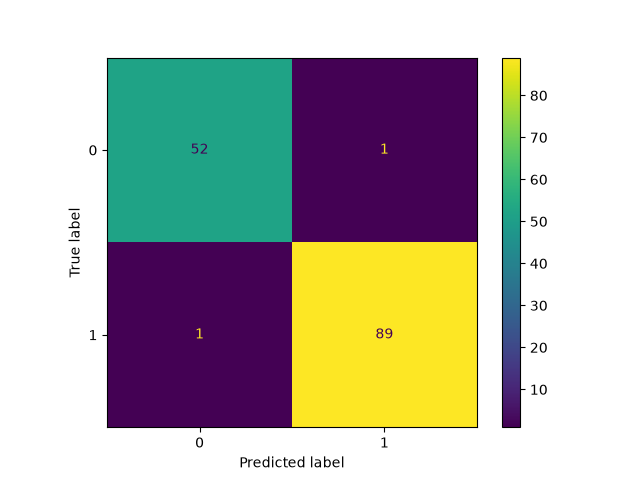

Фильтр по тегу user1: 14


In [16]:
rid=runs['step2']
for i in range(20):
    if tries('step2',rid,'train_tree')>1:break
    rid=trigger('step2','_retry'+str(i));finish('step2',rid)
print('Дерево: попыток',tries('step2',rid,'train_tree'),'| XCom победителя:',xcom('step2',rid,'select_best'))
assert tries('step2',rid,'train_tree')>1
print('Передаются имя и точность, а не строки таблицы.')
def heartbeat_run():
    return next((r for r in api('GET',path('step7')+'/dagRuns?limit=10&order_by=-execution_date')['dag_runs'] if r['state']=='success' and r['run_type']=='scheduled'),None)
hb=wait(heartbeat_run);api('PATCH',path('step7'),json={'is_paused':True}); print('Плановый запуск:',hb['dag_run_id'],xcom('step7',hb['dag_run_id'],'heartbeat'));print('Москва = UTC+3; Airflow отображал UTC.')
keys=[o['Key'] for o in s3.list_objects_v2(Bucket='user1',Prefix='airflow/').get('Contents',[])];print(keys)
cm=next(k for k in sorted(keys,reverse=True) if k.endswith('step4/confusion_matrix.png'));display(Image(s3.get_object(Bucket='user1',Key=cm)['Body'].read()))
print('Фильтр по тегу user1:',len(api('GET','/dags?tags=user1&limit=100')['dags']))

### Диагностика импорта
На короткое время создаём отдельную копию учебного файла с незакрытой скобкой. Не изменяем работающий DAG. После чтения ошибки удаляем временную копию и проверяем очистку списка.

In [17]:
probe=DAG_DIR/'practice_import_probe.py'
def errors():return [e for e in api('GET','/importErrors')['import_errors'] if e['filename'].endswith(probe.name)]
try:
    probe.write_text("from airflow import DAG\nDAG(\n",encoding='utf8');err=wait(errors,180)[0]; print(err['stack_trace'].splitlines()[-1])
finally:probe.unlink(missing_ok=True)
wait(lambda:not errors(),180);print('Ошибка устранена; остальные DAG не изменялись.')

SyntaxError: '(' was never closed


Ошибка устранена; остальные DAG не изменялись.
